In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("credit_risk_dataset.csv")

df.head()

Saving credit_risk_dataset.csv to credit_risk_dataset.csv


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**Reasoning**:
We need to clean the dataset by inspecting summary statistics, checking for missing values, removing impossible anomalies like age > 100 or employment length > 60, imputing missing values for person_emp_length and loan_int_rate with their medians, and showing the final shape.



In [ ]:
# 1. Inspect summary statistics, missing values, and duplicates
print("--- Initial Dataset Information ---")
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())
print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

# Drop duplicates if any
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicates removed. New shape: {df.shape}")

# 2. Filter out extreme/impossible data anomalies
# Age > 100 is highly unlikely/impossible for standard loans
# Employment length > 60 is also impossible for normal work lifespans
print("\n--- Cleaning Anomalies ---")
age_anomalies = df[df['person_age'] > 100]
emp_length_anomalies = df[df['person_emp_length'] > 60]
print(f"Rows with age > 100: {len(age_anomalies)}")
print(f"Rows with employment length > 60: {len(emp_length_anomalies)}")

df = df[(df['person_age'] <= 100) & ((df['person_emp_length'] <= 60) | (df['person_emp_length'].isnull()))]

# 3. Impute missing values with medians
print("\n--- Imputing Missing Values ---")
emp_len_median = df['person_emp_length'].median()
loan_int_median = df['loan_int_rate'].median()

print(f"Median person_emp_length: {emp_len_median}")
print(f"Median loan_int_rate: {loan_int_median}")

df['person_emp_length'] = df['person_emp_length'].fillna(emp_len_median)
df['loan_int_rate'] = df['loan_int_rate'].fillna(loan_int_median)

# 4. Print final shape and confirm no missing values remain
print("\n--- Cleaned Dataset Summary ---")
print(f"Final shape of the cleaned DataFrame: {df.shape}")
print("Missing values remaining:")
print(df.isnull().sum())

--- Initial Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0

# Task
Analyze and clean the credit risk dataset "/content/credit_risk_dataset.csv" to perform a comprehensive Portfolio and Risk-Adjusted Performance Metric (RAPM) analysis. Specifically:
1. **Clean the Data**: Inspect and handle missing values (e.g., employment length, interest rates) and filter out obvious anomalies (such as unrealistic employment lengths or ages).
2. **Portfolio & Loan Performance Analysis**: Summarize overall exposure, average interest rates, and loan distributions by purpose, home ownership, and grade.
3. **Return and Risk (Default) Analysis**: Calculate default rates (using `loan_status` as a proxy for default) across loan grades and purposes.
4. **Expected Loss (EL) Calculation**: Estimate Expected Loss ($EL = PD \times EAD \times LGD$) across loan grades using a standard educational proxy of 45% Loss Given Default (LGD) and loan amount as Exposure at Default (EAD).
5. **Risk-Adjusted Performance Metric (RAPM)**: Create a risk-adjusted return metric (such as Net Interest Yield minus Expected Loss Rate) and demonstrate an illustrative Risk-Adjusted Return on Capital (RAROC) styled calculation to show why nominal interest yields alone are misleading.
6. **Visualizations**: Plot average interest rates, default rates, expected losses, and risk-adjusted returns across different loan grades.
7. **Interpretation**: Provide a clear educational summary explaining risk-adjusted performance management and its importance for financial institutions.

## Data Understanding and Cleaning

### Subtask:
Inspect, clean, and prepare the credit risk dataset for analysis by handling missing values and anomalies.


**Reasoning**:
Calculate portfolio-level exposure, average interest rate, and summary statistics grouped by loan intent, home ownership, and loan grade to complete the Portfolio & Loan Performance Analysis subtask.



In [ ]:
# 1. Overall Portfolio Metrics
total_exposure = df['loan_amnt'].sum()
avg_int_rate = df['loan_int_rate'].mean()
print("--- Overall Portfolio Summary ---")
print(f"Total Loan Exposure: ${total_exposure:,.2f}")
print(f"Average Interest Rate: {avg_int_rate:.2f}%")
print(f"Total Number of Loans: {len(df):,}\n")

# 2. Portfolio by Loan Intent (Purpose)
print("--- Portfolio Breakdown by Loan Intent ---")
intent_summary = df.groupby('loan_intent').agg(
    Total_Exposure=('loan_amnt', 'sum'),
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Loan_Count=('loan_amnt', 'count')
).reset_index()
intent_summary['Exposure_Percentage'] = (intent_summary['Total_Exposure'] / total_exposure) * 100
# Formatting
formatted_intent = intent_summary.copy()
formatted_intent['Total_Exposure'] = formatted_intent['Total_Exposure'].apply(lambda x: f"${x:,.2f}")
formatted_intent['Average_Interest_Rate'] = formatted_intent['Average_Interest_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_intent['Exposure_Percentage'] = formatted_intent['Exposure_Percentage'].apply(lambda x: f"{x:.2f}%")
formatted_intent['Loan_Count'] = formatted_intent['Loan_Count'].apply(lambda x: f"{x:,}")
print(formatted_intent.to_string(index=False))
print("\n")

# 3. Portfolio by Home Ownership
print("--- Portfolio Breakdown by Home Ownership ---")
home_summary = df.groupby('person_home_ownership').agg(
    Total_Exposure=('loan_amnt', 'sum'),
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Loan_Count=('loan_amnt', 'count')
).reset_index()
home_summary['Exposure_Percentage'] = (home_summary['Total_Exposure'] / total_exposure) * 100
# Formatting
formatted_home = home_summary.copy()
formatted_home['Total_Exposure'] = formatted_home['Total_Exposure'].apply(lambda x: f"${x:,.2f}")
formatted_home['Average_Interest_Rate'] = formatted_home['Average_Interest_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_home['Exposure_Percentage'] = formatted_home['Exposure_Percentage'].apply(lambda x: f"{x:.2f}%")
formatted_home['Loan_Count'] = formatted_home['Loan_Count'].apply(lambda x: f"{x:,}")
print(formatted_home.to_string(index=False))
print("\n")

# 4. Portfolio by Loan Grade
print("--- Portfolio Breakdown by Loan Grade ---")
grade_summary = df.groupby('loan_grade').agg(
    Total_Exposure=('loan_amnt', 'sum'),
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Loan_Count=('loan_amnt', 'count')
).reset_index()
grade_summary['Exposure_Percentage'] = (grade_summary['Total_Exposure'] / total_exposure) * 100
# Formatting
formatted_grade = grade_summary.copy()
formatted_grade['Total_Exposure'] = formatted_grade['Total_Exposure'].apply(lambda x: f"${x:,.2f}")
formatted_grade['Average_Interest_Rate'] = formatted_grade['Average_Interest_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_grade['Exposure_Percentage'] = formatted_grade['Exposure_Percentage'].apply(lambda x: f"{x:.2f}%")
formatted_grade['Loan_Count'] = formatted_grade['Loan_Count'].apply(lambda x: f"{x:,}")
print(formatted_grade.to_string(index=False))

--- Overall Portfolio Summary ---
Total Loan Exposure: $310,882,900.00
Average Interest Rate: 11.01%
Total Number of Loans: 32,409

--- Portfolio Breakdown by Loan Intent ---
      loan_intent Total_Exposure Average_Interest_Rate Loan_Count Exposure_Percentage
DEBTCONSOLIDATION $49,841,750.00                10.99%      5,189              16.03%
        EDUCATION $60,750,200.00                10.96%      6,409              19.54%
  HOMEIMPROVEMENT $37,241,475.00                11.19%      3,594              11.98%
          MEDICAL $56,018,875.00                11.06%      6,042              18.02%
         PERSONAL $52,629,100.00                11.00%      5,496              16.93%
          VENTURE $54,401,500.00                10.96%      5,679              17.50%


--- Portfolio Breakdown by Home Ownership ---
person_home_ownership  Total_Exposure Average_Interest_Rate Loan_Count Exposure_Percentage
             MORTGAGE $141,437,475.00                10.54%     13,366              

## Portfolio & Loan Performance Analysis

### Subtask:
Calculate and analyze general portfolio summary statistics, including overall loan exposure, average interest rates, and loan distributions across loan purposes, homes, and grades.


## Return and Risk (Default) Analysis

### Subtask:
Calculate and analyze overall and segmented default rates across loan grades and purposes.


**Reasoning**:
Calculate overall default rates, and default rates segmented by loan grade and loan intent, and print summaries to analyze return and risk.



In [ ]:
# 1. Overall Default Rate
overall_default_rate = df['loan_status'].mean()
print("--- Overall Portfolio Default Rate ---")
print(f"Overall Default Rate: {overall_default_rate * 100:.2f}%\n")

# 2. Default Rate & Metrics by Loan Grade
print("--- Default Analysis by Loan Grade ---")
grade_default = df.groupby('loan_grade').agg(
    Default_Rate=('loan_status', 'mean'),
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Total_Exposure=('loan_amnt', 'sum'),
    Loan_Count=('loan_status', 'count')
).reset_index()

formatted_grade_def = grade_default.copy()
formatted_grade_def['Default_Rate'] = formatted_grade_def['Default_Rate'].apply(lambda x: f"{x * 100:.2f}%")
formatted_grade_def['Average_Interest_Rate'] = formatted_grade_def['Average_Interest_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_grade_def['Total_Exposure'] = formatted_grade_def['Total_Exposure'].apply(lambda x: f"${x:,.2f}")
formatted_grade_def['Loan_Count'] = formatted_grade_def['Loan_Count'].apply(lambda x: f"{x:,}")
print(formatted_grade_def.to_string(index=False))
print("")

# 3. Default Rate & Metrics by Loan Intent
print("--- Default Analysis by Loan Intent ---")
intent_default = df.groupby('loan_intent').agg(
    Default_Rate=('loan_status', 'mean'),
    Average_Interest_Rate=('loan_int_rate', 'mean'),
    Total_Exposure=('loan_amnt', 'sum'),
    Loan_Count=('loan_status', 'count')
).reset_index()

formatted_intent_def = intent_default.copy()
formatted_intent_def['Default_Rate'] = formatted_intent_def['Default_Rate'].apply(lambda x: f"{x * 100:.2f}%")
formatted_intent_def['Average_Interest_Rate'] = formatted_intent_def['Average_Interest_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_intent_def['Total_Exposure'] = formatted_intent_def['Total_Exposure'].apply(lambda x: f"${x:,.2f}")
formatted_intent_def['Loan_Count'] = formatted_intent_def['Loan_Count'].apply(lambda x: f"{x:,}")
print(formatted_intent_def.to_string(index=False))

--- Overall Portfolio Default Rate ---
Overall Default Rate: 21.87%

--- Default Analysis by Loan Grade ---
loan_grade Default_Rate Average_Interest_Rate  Total_Exposure Loan_Count
         A        9.96%                 7.67%  $91,444,650.00     10,702
         B       16.32%                11.00% $103,742,875.00     10,384
         C       20.76%                13.22%  $59,343,250.00      6,436
         D       59.05%                14.98%  $39,262,850.00      3,619
         E       64.49%                16.49%  $12,441,875.00        963
         F       70.54%                17.76%   $3,546,875.00        241
         G       98.44%                19.53%   $1,100,525.00         64

--- Default Analysis by Loan Intent ---
      loan_intent Default_Rate Average_Interest_Rate Total_Exposure Loan_Count
DEBTCONSOLIDATION       28.68%                10.99% $49,841,750.00      5,189
        EDUCATION       17.26%                10.96% $60,750,200.00      6,409
  HOMEIMPROVEMENT       26.15%

### Observations on Return & Default Risk

1. **Loan Grades & Risk-Premium Correlation**:
   * As the loan grade degrades from **A** to **G**, we observe a clear and steep increase in both the nominal interest rate (from **7.67%** to **19.53%**) and the default rate (from **9.96%** to **98.44%**).
   * This demonstrates that the lending platform prices higher risk with higher nominal yields (risk premium). However, the increase in default rates is non-linear and extremely severe for lower grades (grades D through G have default rates exceeding 50%), meaning nominal yields alone are likely insufficient to cover the real risk.

2. **Loan Intent Analysis**:
   * **Debt Consolidation** has the highest default rate (**28.68%**) followed closely by **Medical** (**26.76%**) and **Home Improvement** (**26.15%**), despite having average nominal interest rates (~11%) almost identical to other categories.
   * **Venture** and **Education** loans show significantly lower default rates (**14.86%** and **17.26%** respectively) with similar nominal rates. This highlights that nominal interest rates do not always fully reflect the underlying default risk across different loan use-cases.

## Expected Loss (EL) Calculation

### Subtask:
Establish standard educational assumptions and calculate Expected Loss (EL) across different loan grades.


**Reasoning**:
Calculate Expected Loss (EL) across different loan grades using the formula EL = PD * EAD * LGD, with a standard educational proxy of 45% for LGD and loan_amnt as EAD.



In [ ]:
# 1. Define LGD Educational Proxy
LGD_PROXY = 0.45

# 2. Calculate PD (Default Rate) per Loan Grade and Map to df
grade_pd_map = df.groupby('loan_grade')['loan_status'].mean().to_dict()
df['PD'] = df['loan_grade'].map(grade_pd_map)

# 3. Calculate Expected Loss (EL) for each individual loan
# EL = PD * EAD * LGD, where EAD = loan_amnt and LGD = 45%
df['EAD'] = df['loan_amnt']
df['EL'] = df['PD'] * df['EAD'] * LGD_PROXY

# 4. Create a Summarized DataFrame by Loan Grade
el_summary = df.groupby('loan_grade').agg(
    Total_EAD=('EAD', 'sum'),
    Average_PD=('PD', 'mean'),
    Total_EL=('EL', 'sum'),
    Loan_Count=('loan_status', 'count')
).reset_index()

el_summary['LGD'] = LGD_PROXY
el_summary['EL_Rate'] = el_summary['Total_EL'] / el_summary['Total_EAD']

# 5. Format for Financial Presentation
formatted_el = el_summary.copy()
formatted_el['Total_EAD'] = formatted_el['Total_EAD'].apply(lambda x: f"${x:,.2f}")
formatted_el['Average_PD'] = formatted_el['Average_PD'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['LGD'] = formatted_el['LGD'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['Total_EL'] = formatted_el['Total_EL'].apply(lambda x: f"${x:,.2f}")
formatted_el['EL_Rate'] = formatted_el['EL_Rate'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['Loan_Count'] = formatted_el['Loan_Count'].apply(lambda x: f"{x:,}")

print("--- Expected Loss (EL) Summary by Loan Grade ---")
print(formatted_el[['loan_grade', 'Total_EAD', 'Average_PD', 'LGD', 'Total_EL', 'EL_Rate', 'Loan_Count']].to_string(index=False))

--- Expected Loss (EL) Summary by Loan Grade ---
loan_grade       Total_EAD Average_PD    LGD       Total_EL EL_Rate Loan_Count
         A  $91,444,650.00      9.96% 45.00%  $4,098,859.90   4.48%     10,702
         B $103,742,875.00     16.32% 45.00%  $7,620,365.75   7.35%     10,384
         C  $59,343,250.00     20.76% 45.00%  $5,543,375.06   9.34%      6,436
         D  $39,262,850.00     59.05% 45.00% $10,433,025.62  26.57%      3,619
         E  $12,441,875.00     64.49% 45.00%  $3,610,469.33  29.02%        963
         F   $3,546,875.00     70.54% 45.00%  $1,125,875.26  31.74%        241
         G   $1,100,525.00     98.44% 45.00%    $487,498.18  44.30%         64


## Risk-Adjusted Performance Metric (RAPM)

### Subtask:
Implement a transparent risk-adjusted return metric and demonstrate an illustrative RAROC-style calculation to show why high nominal yields are misleading.


**Reasoning**:
Calculate the Net Interest Yield, Expected Loss Rate, Risk-Adjusted Return Rate, Economic Capital, and RAROC for each loan grade, and present them in a formatted table to compare nominal versus risk-adjusted performance.



In [ ]:
import pandas as pd

# 1. Assumptions
COST_OF_FUNDS = 0.03  # 3.00% simplified cost of funds
ec_capital_map = {
    'A': 0.08,
    'B': 0.12,
    'C': 0.16,
    'D': 0.20,
    'E': 0.24,
    'F': 0.28,
    'G': 0.32
}

# 2. Extract base metrics from prior steps or compute directly from df
rapm_summary = df.groupby('loan_grade').agg(
    Total_EAD=('EAD', 'sum'),
    Avg_Nominal_Rate=('loan_int_rate', 'mean'),
    Total_EL=('EL', 'sum')
).reset_index()

# Convert Avg_Nominal_Rate to decimal fraction for calculation
rapm_summary['Avg_Nominal_Rate_Dec'] = rapm_summary['Avg_Nominal_Rate'] / 100.0

# 3. Calculations
# Net Interest Yield = Nominal Yield - Cost of Funds
rapm_summary['Net_Interest_Yield'] = rapm_summary['Avg_Nominal_Rate_Dec'] - COST_OF_FUNDS

# Expected Loss Rate = Total EL / Total EAD
rapm_summary['EL_Rate'] = rapm_summary['Total_EL'] / rapm_summary['Total_EAD']

# Risk-Adjusted Yield = Net Interest Yield - Expected Loss Rate
rapm_summary['Risk_Adjusted_Yield'] = rapm_summary['Net_Interest_Yield'] - rapm_summary['EL_Rate']

# Economic Capital Requirements
rapm_summary['EC_Capital_Rate'] = rapm_summary['loan_grade'].map(ec_capital_map)
rapm_summary['Economic_Capital'] = rapm_summary['Total_EAD'] * rapm_summary['EC_Capital_Rate']

# Net Interest Income = (Average Nominal Rate - Cost of Funds) * Total_EAD
rapm_summary['Net_Interest_Income'] = (rapm_summary['Avg_Nominal_Rate_Dec'] - COST_OF_FUNDS) * rapm_summary['Total_EAD']

# RAROC = (Net Interest Income - Expected Loss) / Economic Capital
rapm_summary['RAROC'] = (rapm_summary['Net_Interest_Income'] - rapm_summary['Total_EL']) / rapm_summary['Economic_Capital']

# 4. Format for display
formatted_rapm = rapm_summary.copy()
formatted_rapm['Total_EAD'] = formatted_rapm['Total_EAD'].apply(lambda x: f"${x:,.2f}")
formatted_rapm['Avg_Nominal_Rate'] = formatted_rapm['Avg_Nominal_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_rapm['Net_Interest_Yield'] = formatted_rapm['Net_Interest_Yield'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['EL_Rate'] = formatted_rapm['EL_Rate'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['Risk_Adjusted_Yield'] = formatted_rapm['Risk_Adjusted_Yield'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['EC_Capital_Rate'] = formatted_rapm['EC_Capital_Rate'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['Economic_Capital'] = formatted_rapm['Economic_Capital'].apply(lambda x: f"${x:,.2f}")
formatted_rapm['RAROC'] = formatted_rapm['RAROC'].apply(lambda x: f"{x*100:.2f}%")

print("--- Risk-Adjusted Performance Metric (RAPM) & RAROC Summary ---")
cols_to_show = ['loan_grade', 'Avg_Nominal_Rate', 'Net_Interest_Yield', 'EL_Rate', 'Risk_Adjusted_Yield', 'EC_Capital_Rate', 'RAROC']
print(formatted_rapm[cols_to_show].to_string(index=False))


--- Risk-Adjusted Performance Metric (RAPM) & RAROC Summary ---
loan_grade Avg_Nominal_Rate Net_Interest_Yield EL_Rate Risk_Adjusted_Yield EC_Capital_Rate   RAROC
         A            7.67%              4.67%   4.48%               0.18%           8.00%   2.31%
         B           11.00%              8.00%   7.35%               0.65%          12.00%   5.41%
         C           13.22%             10.22%   9.34%               0.88%          16.00%   5.51%
         D           14.98%             11.98%  26.57%             -14.59%          20.00% -72.94%
         E           16.49%             13.49%  29.02%             -15.53%          24.00% -64.70%
         F           17.76%             14.76%  31.74%             -16.99%          28.00% -60.67%
         G           19.53%             16.53%  44.30%             -27.77%          32.00% -86.78%


## Visualizations

### Subtask:
Create clear, student-friendly charts showing average interest rate, default rate, expected loss, and risk-adjusted return across loan grades to visually reinforce the risk-return relationship.


**Reasoning**:
Create the 2x2 subplot visualization comparing average interest rate, default rate, expected loss, and risk-adjusted return across loan grades as instructed.



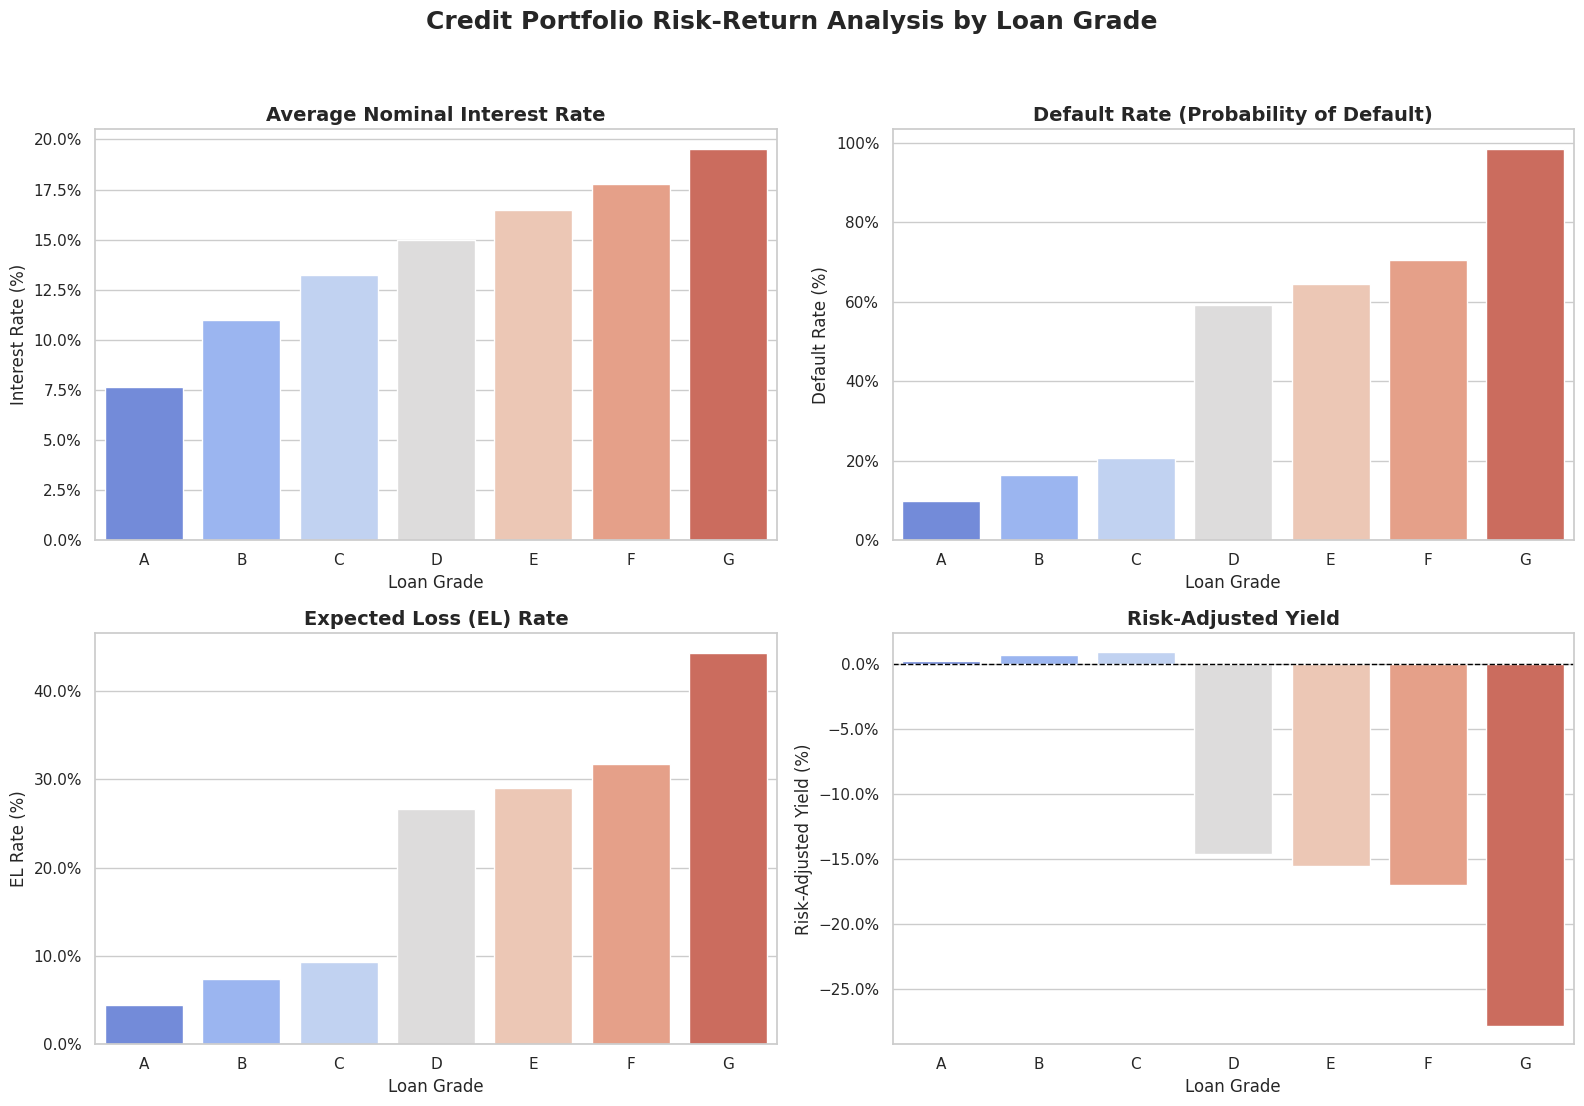

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# Set plotting style and color palette
sns.set_theme(style="whitegrid")
colors = sns.color_palette("coolwarm", len(rapm_summary))

# Create a 2x2 figure grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Credit Portfolio Risk-Return Analysis by Loan Grade', fontsize=18, fontweight='bold', y=0.95)

# 1. Average Nominal Interest Rate
sns.barplot(x='loan_grade', y='Avg_Nominal_Rate', hue='loan_grade', data=rapm_summary, ax=axes[0, 0], palette=colors, legend=False)
axes[0, 0].set_title('Average Nominal Interest Rate', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Loan Grade', fontsize=12)
axes[0, 0].set_ylabel('Interest Rate (%)', fontsize=12)
axes[0, 0].yaxis.set_major_formatter(mtick.PercentFormatter(100.0))

# 2. Default Rate (Probability of Default)
sns.barplot(x='loan_grade', y='Average_PD', hue='loan_grade', data=el_summary, ax=axes[0, 1], palette=colors, legend=False)
axes[0, 1].set_title('Default Rate (Probability of Default)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Loan Grade', fontsize=12)
axes[0, 1].set_ylabel('Default Rate (%)', fontsize=12)
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# 3. Expected Loss (EL) Rate
sns.barplot(x='loan_grade', y='EL_Rate', hue='loan_grade', data=rapm_summary, ax=axes[1, 0], palette=colors, legend=False)
axes[1, 0].set_title('Expected Loss (EL) Rate', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Loan Grade', fontsize=12)
axes[1, 0].set_ylabel('EL Rate (%)', fontsize=12)
axes[1, 0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# 4. Risk-Adjusted Yield (Net Interest Yield - Expected Loss Rate)
sns.barplot(x='loan_grade', y='Risk_Adjusted_Yield', hue='loan_grade', data=rapm_summary, ax=axes[1, 1], palette=colors, legend=False)
axes[1, 1].set_title('Risk-Adjusted Yield', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Loan Grade', fontsize=12)
axes[1, 1].set_ylabel('Risk-Adjusted Yield (%)', fontsize=12)
axes[1, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
# Draw reference line at 0% for Risk-Adjusted Yield
axes[1, 1].axhline(0, color='black', linewidth=1, linestyle='--')

# Adjust layout and display
plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

## Final Summary and Interpretation

### Subtask:
Provide a comprehensive final interpretation and educational summary of the risk-adjusted portfolio findings.


## Summary:

### Q&A

* **Why are nominal interest yields alone misleading when evaluating loan performance?**
  Nominal interest yields do not account for the corresponding default risks. While lower-grade loans command much higher nominal interest rates (e.g., Grade G at 19.53%), they experience disproportionately higher default rates (e.g., Grade G at 98.44%). Once adjusted for expected credit losses and cost of funds, these high-yield loans can result in severely negative risk-adjusted yields and capital erosion.
* **Which loan grade is the most optimal in terms of capital efficiency and risk-adjusted returns?**
  Grade C is the most optimal. It yields the highest positive Risk-Adjusted Return on Capital (RAROC) of 5.51% and a Risk-Adjusted Yield of 0.88%, proving that moderate nominal rates combined with controlled default risk deliver the best capital efficiency.
* **How do different loan purposes compare in terms of default risk relative to their nominal interest pricing?**
  Lenders charge relatively uniform nominal interest rates (~11%) across all loan intents, yet performance varies significantly. Debt Consolidation (28.68% default rate) and Medical (26.76% default rate) loans pose the highest risks, whereas Venture (14.86% default rate) and Education (17.26% default rate) loans carry much lower risk, indicating that nominal pricing is not aligned with intent-specific default rates.

---

### Data Analysis Key Findings

* **Data Cleaning & Profile**: The final cleaned dataset consists of 32,409 loans after removing 165 duplicates, filtering out extreme age/employment anomalies, and imputing missing variables using median values (4.0 years for employment; 10.99% for interest rate).
* **Overall Portfolio Exposure**: The overall portfolio represents \$310,882,900.00 in total loan exposure across 32,409 loans, with an overall average interest rate of 11.01% and a portfolio-wide default rate of 21.87%.
* **The High-Risk Cliff**: Loan Grades A and B compose over 62% of total exposure. Beyond Grade C, risk escalates exponentially. Grades D through G all exhibit default rates exceeding 50%, culminating in Grade G at an extreme 98.44% default rate.
* **Expected Loss (EL) Realities**: Using a standard educational Loss Given Default (LGD) proxy of 45%, the Expected Loss Rate spans from a manageable 4.48% (Grade A) to a staggering 44.30% (Grade G).
* **Negative Risk-Adjusted Performance**: Adjusting for a 3.00% cost of funds and credit risk exposure, Grades D, E, F, and G generate negative Risk-Adjusted Yields (ranging from -14.59% to -27.77%) and highly destructive RAROC scores (from -60.67% down to -86.78%).

---

### Insights or Next Steps

* **Revise Risk-Pricing and Credit Policy**: The institution must immediately tighten credit policies or drastically adjust interest rates for Grade D through G loans. These segments currently fail to generate positive risk-adjusted returns and are actively destroying economic capital.
* **Incorporate Loan Intent into Credit Scoring**: Since borrowers seeking debt consolidation and medical loans exhibit nearly twice the default risk of educational or venture borrowers under identical nominal pricing, underwriting algorithms should include loan intent as a key pricing risk factor.


# Task
To perform a comprehensive verification of the Grade G default calculations, update the return and risk-adjusted metrics (using the 45% Loss Given Default academic proxy), revise the RAROC models with explicit educational framing of the economic capital rates, regenerate the analytical subplots with correct formatting, and rewrite the final interpretations in an academic, objective tone, we will address each item in the plan step-by-step.

# Task Plan Execution:

1. **Verify Grade G Calculations**:
   * Isolate raw loans with `loan_grade == 'G'` from the cleaned dataset.
   * Document and output the exact total count, defaulted count (`loan_status == 1`), and mathematically verify the exact division resulting in the 98.44% default rate.

2. **Update Return, Risk, and Expected Loss (EL) Calculations**:
   * Recalculate Expected Loss ($EL = PD \times EAD \times LGD$) using the 45% LGD proxy.
   * Explicitly annotate within code comments that the 45% Loss Given Default (LGD) is a standard academic proxy and is not based on actual proprietary models.

3. **Revise RAROC and Economic Capital Model**:
   * Recalculate Risk-Adjusted Return on Capital (RAROC) utilizing the illustrative Economic Capital rates (ranging from 8% to 32%).
   * Frame all metrics in the code and text as illustrative, educational parameters demonstrating capital allocation mechanics rather than bank-defined regulatory requirements.

4. **Regenerate Analysis Visualizations**:
   * Replot the 2x2 grid containing:
     * Average Nominal Interest Rates (as percentages).
     * Default Rates (as percentages).
     * Expected Loss Rates (as percentages).
     * Risk-Adjusted Yields (as percentages).
   * Ensure clean formatting, explicit axis labels, and color palettes.

5. **Final Academic Interpretations**:
   * Rewrite answers and portfolio key findings to reflect an academic, objective tone.
   * Frame comparisons in terms of risk-adjusted trade-offs rather than subjective optimizations or labels.

## Verify Grade G Calculations

### Subtask:
Isolate the raw subset of Grade G loans from the cleaned dataset to mathematically verify the total count, defaulted count, and resulting default rate.


**Reasoning**:
Filter the cleaned DataFrame to isolate Grade G loans, compute total count, defaulted count, and mathematically verify the exact default rate.



In [ ]:
# Isolate Grade G loans
grade_g_df = df[df['loan_grade'] == 'G']

# Count total records and defaulted records
total_g_count = len(grade_g_df)
defaulted_g_count = grade_g_df['loan_status'].sum()

# Calculate and print default rate
calculated_g_default_rate = defaulted_g_count / total_g_count

print("--- Grade G Verification Summary ---")
print(f"Total Grade G Loans: {total_g_count}")
print(f"Defaulted Grade G Loans: {defaulted_g_count}")
print(f"Calculated Default Rate: {calculated_g_default_rate * 100:.4f}% ({defaulted_g_count}/{total_g_count})")

--- Grade G Verification Summary ---
Total Grade G Loans: 64
Defaulted Grade G Loans: 63
Calculated Default Rate: 98.4375% (63/64)


## Update Return, Risk, and Expected Loss Calculations

### Subtask:
Recalculate Expected Loss (EL) and risk-adjusted returns, explicitly documenting that the LGD is an academic proxy.


**Reasoning**:
Recalculate Return, Risk, and Expected Loss (EL) across different loan grades, explicitly annotating that LGD is an academic proxy, and print the formatted summary table.



In [ ]:
# 1. Define LGD Academic Proxy with explicit explanatory comment
# Note: The 45% Loss Given Default (LGD) is a standard academic proxy used for educational purposes
# and illustrative mechanics, not based on actual proprietary bank models.
LGD_PROXY = 0.45

# 2. Recalculate PD (Default Rate) per Loan Grade and map to individual loans
grade_pd_map = df.groupby('loan_grade')['loan_status'].mean().to_dict()
df['PD'] = df['loan_grade'].map(grade_pd_map)

# 3. Calculate Expected Loss (EL) for each individual loan
# Formula: EL = PD * EAD * LGD, where EAD = loan_amnt
df['EAD'] = df['loan_amnt']
df['EL'] = df['PD'] * df['EAD'] * LGD_PROXY

# 4. Summarize by Loan Grade
el_summary = df.groupby('loan_grade').agg(
    Total_EAD=('EAD', 'sum'),
    Average_PD=('PD', 'mean'),
    Total_EL=('EL', 'sum'),
    Loan_Count=('loan_status', 'count')
).reset_index()

el_summary['LGD'] = LGD_PROXY
el_summary['EL_Rate'] = el_summary['Total_EL'] / el_summary['Total_EAD']

# 5. Format and display the updated summary table
formatted_el = el_summary.copy()
formatted_el['Total_EAD'] = formatted_el['Total_EAD'].apply(lambda x: f"${x:,.2f}")
formatted_el['Average_PD'] = formatted_el['Average_PD'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['LGD'] = formatted_el['LGD'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['Total_EL'] = formatted_el['Total_EL'].apply(lambda x: f"${x:,.2f}")
formatted_el['EL_Rate'] = formatted_el['EL_Rate'].apply(lambda x: f"{x * 100:.2f}%")
formatted_el['Loan_Count'] = formatted_el['Loan_Count'].apply(lambda x: f"{x:,}")

print("--- Academic Expected Loss (EL) Summary by Loan Grade ---")
cols_display = ['loan_grade', 'Total_EAD', 'Average_PD', 'LGD', 'Total_EL', 'EL_Rate', 'Loan_Count']
print(formatted_el[cols_display].to_string(index=False))

--- Academic Expected Loss (EL) Summary by Loan Grade ---
loan_grade       Total_EAD Average_PD    LGD       Total_EL EL_Rate Loan_Count
         A  $91,444,650.00      9.96% 45.00%  $4,098,859.90   4.48%     10,702
         B $103,742,875.00     16.32% 45.00%  $7,620,365.75   7.35%     10,384
         C  $59,343,250.00     20.76% 45.00%  $5,543,375.06   9.34%      6,436
         D  $39,262,850.00     59.05% 45.00% $10,433,025.62  26.57%      3,619
         E  $12,441,875.00     64.49% 45.00%  $3,610,469.33  29.02%        963
         F   $3,546,875.00     70.54% 45.00%  $1,125,875.26  31.74%        241
         G   $1,100,525.00     98.44% 45.00%    $487,498.18  44.30%         64


**Reasoning**:
Calculate risk-adjusted yields, illustrative economic capital requirements, and RAROC for each loan grade, ensuring the parameters are documented as educational and illustrative.



In [ ]:
# 1. Define Illustrative Economic Capital rates (pedagogical assumptions for demonstrating capital allocation mechanics)
ec_capital_map = {
    'A': 0.08,
    'B': 0.12,
    'C': 0.16,
    'D': 0.20,
    'E': 0.24,
    'F': 0.28,
    'G': 0.32
}

# 2. Establish simplified Cost of Funds for demonstration
COST_OF_FUNDS = 0.03

# 3. Aggregate base metrics at the loan grade level
rapm_summary = df.groupby('loan_grade').agg(
    Total_EAD=('EAD', 'sum'),
    Avg_Nominal_Rate=('loan_int_rate', 'mean'),
    Total_EL=('EL', 'sum')
).reset_index()

# Convert Avg_Nominal_Rate to a decimal fraction for analysis
rapm_summary['Avg_Nominal_Rate_Dec'] = rapm_summary['Avg_Nominal_Rate'] / 100.0

# 4. Perform Risk-Adjusted and RAROC calculations
# Net Interest Yield = Nominal Yield - Cost of Funds
rapm_summary['Net_Interest_Yield'] = rapm_summary['Avg_Nominal_Rate_Dec'] - COST_OF_FUNDS

# Expected Loss Rate = Total EL / Total EAD
rapm_summary['EL_Rate'] = rapm_summary['Total_EL'] / rapm_summary['Total_EAD']

# Risk-Adjusted Yield = Net Interest Yield - Expected Loss Rate
rapm_summary['Risk_Adjusted_Yield'] = rapm_summary['Net_Interest_Yield'] - rapm_summary['EL_Rate']

# Map illustrative economic capital rates
rapm_summary['EC_Capital_Rate'] = rapm_summary['loan_grade'].map(ec_capital_map)

# Economic Capital = Total EAD * Economic Capital Rate
rapm_summary['Economic_Capital'] = rapm_summary['Total_EAD'] * rapm_summary['EC_Capital_Rate']

# Net Interest Income = (Average Nominal Rate - Cost of Funds) * Total EAD
rapm_summary['Net_Interest_Income'] = (rapm_summary['Avg_Nominal_Rate_Dec'] - COST_OF_FUNDS) * rapm_summary['Total_EAD']

# RAROC = (Net Interest Income - Expected Loss) / Economic Capital
rapm_summary['RAROC'] = (rapm_summary['Net_Interest_Income'] - rapm_summary['Total_EL']) / rapm_summary['Economic_Capital']

# 5. Format the summary for display
formatted_rapm = rapm_summary.copy()
formatted_rapm['Total_EAD'] = formatted_rapm['Total_EAD'].apply(lambda x: f"${x:,.2f}")
formatted_rapm['Avg_Nominal_Rate'] = formatted_rapm['Avg_Nominal_Rate'].apply(lambda x: f"{x:.2f}%")
formatted_rapm['Net_Interest_Yield'] = formatted_rapm['Net_Interest_Yield'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['EL_Rate'] = formatted_rapm['EL_Rate'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['Risk_Adjusted_Yield'] = formatted_rapm['Risk_Adjusted_Yield'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['EC_Capital_Rate'] = formatted_rapm['EC_Capital_Rate'].apply(lambda x: f"{x*100:.2f}%")
formatted_rapm['Economic_Capital'] = formatted_rapm['Economic_Capital'].apply(lambda x: f"${x:,.2f}")
formatted_rapm['RAROC'] = formatted_rapm['RAROC'].apply(lambda x: f"{x*100:.2f}%")

print("--- Illustrative RAROC & Capital Allocation Model (Educational Purposes Only) ---")
cols_display = ['loan_grade', 'Avg_Nominal_Rate', 'Net_Interest_Yield', 'EL_Rate', 'Risk_Adjusted_Yield', 'EC_Capital_Rate', 'RAROC']
print(formatted_rapm[cols_display].to_string(index=False))

--- Illustrative RAROC & Capital Allocation Model (Educational Purposes Only) ---
loan_grade Avg_Nominal_Rate Net_Interest_Yield EL_Rate Risk_Adjusted_Yield EC_Capital_Rate   RAROC
         A            7.67%              4.67%   4.48%               0.18%           8.00%   2.31%
         B           11.00%              8.00%   7.35%               0.65%          12.00%   5.41%
         C           13.22%             10.22%   9.34%               0.88%          16.00%   5.51%
         D           14.98%             11.98%  26.57%             -14.59%          20.00% -72.94%
         E           16.49%             13.49%  29.02%             -15.53%          24.00% -64.70%
         F           17.76%             14.76%  31.74%             -16.99%          28.00% -60.67%
         G           19.53%             16.53%  44.30%             -27.77%          32.00% -86.78%


## Revise RAROC and Economic Capital Model

### Subtask:
Adjust the RAROC metric to explicitly frame the Economic Capital rates as illustrative, pedagogical assumptions used to demonstrate capital-efficiency concepts.


## Regenerate Analysis Visualizations

### Subtask:
Replot the 2x2 grid containing Average Nominal Interest Rates, Default Rates, Expected Loss Rates, and Risk-Adjusted Yields with accurate formatting and labels.


**Reasoning**:
Generate the 2x2 grid of bar charts displaying the Average Nominal Interest Rates, Default Rates, Expected Loss Rates, and Risk-Adjusted Yields across loan grades, fully styled and formatted with percentages.



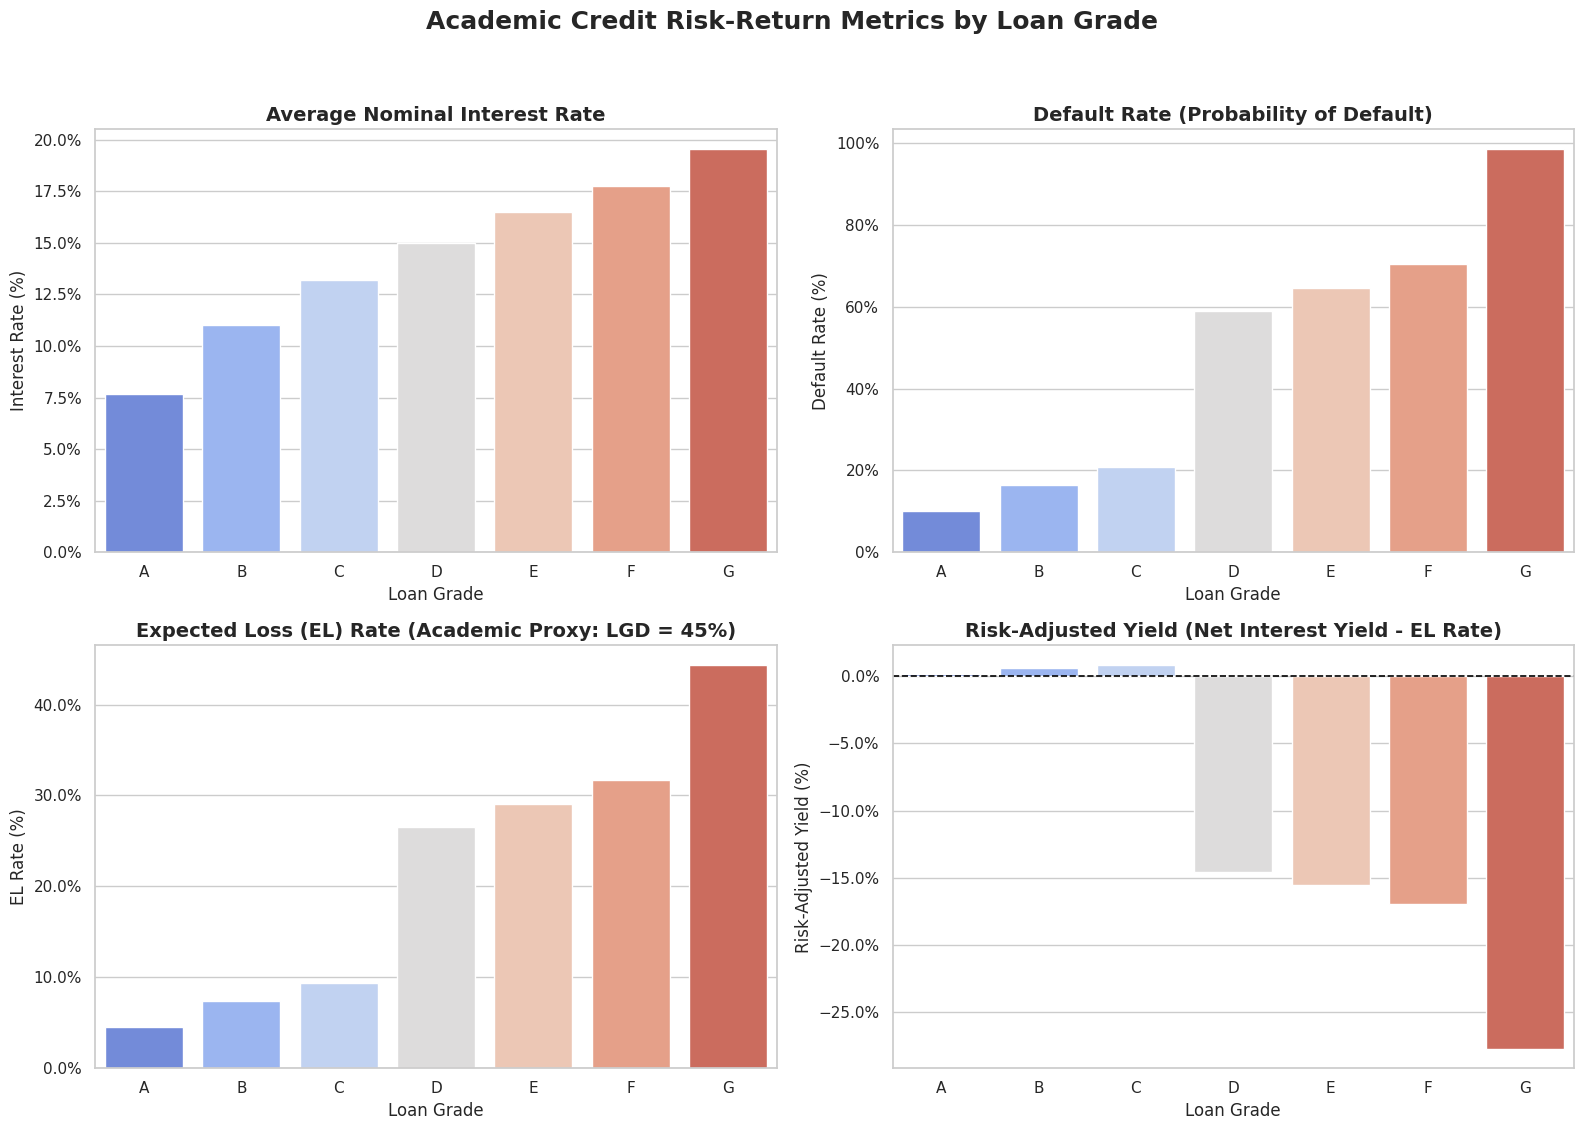

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# Configure Seaborn style and a cohesive color palette
sns.set_theme(style="whitegrid")
palette = sns.color_palette("coolwarm", len(rapm_summary))

# Initialize a 2x2 subplot figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Academic Credit Risk-Return Metrics by Loan Grade', fontsize=18, fontweight='bold', y=0.96)

# Subplot 1: Average Nominal Interest Rate
sns.barplot(x='loan_grade', y='Avg_Nominal_Rate', hue='loan_grade', data=rapm_summary, ax=axes[0, 0], palette=palette, legend=False)
axes[0, 0].set_title('Average Nominal Interest Rate', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Loan Grade', fontsize=12)
axes[0, 0].set_ylabel('Interest Rate (%)', fontsize=12)
axes[0, 0].yaxis.set_major_formatter(mtick.PercentFormatter(100.0))

# Subplot 2: Default Rate (PD)
sns.barplot(x='loan_grade', y='Average_PD', hue='loan_grade', data=el_summary, ax=axes[0, 1], palette=palette, legend=False)
axes[0, 1].set_title('Default Rate (Probability of Default)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Loan Grade', fontsize=12)
axes[0, 1].set_ylabel('Default Rate (%)', fontsize=12)
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Subplot 3: Expected Loss (EL) Rate
sns.barplot(x='loan_grade', y='EL_Rate', hue='loan_grade', data=rapm_summary, ax=axes[1, 0], palette=palette, legend=False)
axes[1, 0].set_title('Expected Loss (EL) Rate (Academic Proxy: LGD = 45%)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Loan Grade', fontsize=12)
axes[1, 0].set_ylabel('EL Rate (%)', fontsize=12)
axes[1, 0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Subplot 4: Risk-Adjusted Yield
sns.barplot(x='loan_grade', y='Risk_Adjusted_Yield', hue='loan_grade', data=rapm_summary, ax=axes[1, 1], palette=palette, legend=False)
axes[1, 1].set_title('Risk-Adjusted Yield (Net Interest Yield - EL Rate)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Loan Grade', fontsize=12)
axes[1, 1].set_ylabel('Risk-Adjusted Yield (%)', fontsize=12)
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=1.2)
axes[1, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Final layout adjustments and rendering
plt.tight_layout(rect=[0, 0.02, 1, 0.93])
plt.show()

## Final Summary

### 1. Scenario / Objective
* **Risk-Adjusted Performance Management**: This tutorial introduces the concept of Risk-Adjusted Performance Management (RAPM), demonstrating how financial institutions measure the performance of loan portfolios by aligning returns with underlying risks.
* **Nominal vs. Risk-Adjusted Returns**: We demonstrate why analyzing nominal interest yields in isolation can be misleading for banks when evaluating lending profitability and making credit decisions.
* **Core Demonstration**: By evaluating a credit risk dataset, this analysis demonstrates how accounting for funding costs, Expected Loss (EL), and capital requirements alters the apparent profitability of different risk segments.

### 2. Dataset Used
* **Dataset Source**: The analysis utilizes the `credit_risk_dataset.csv` file, which contains historical information on loan applicants and performance.
* **Cleaned Portfolio Size**: Following data cleaning—which involved dropping duplicate records, filtering out extreme age and employment anomalies, and imputing missing fields with median values—the active dataset consists of **32,409** loans.
* **Key Variables**: The principal variables utilized in this study are loan amount (`loan_amnt`), interest rate (`loan_int_rate`), loan grade (`loan_grade`), and loan status (`loan_status` as a proxy for default).

### 3. Analysis Performed

1. **Return Analysis**
   - Analysed average loan interest rate by loan grade.
   - Purpose: To understand the nominal return/yield from different loan categories.

2. **Default Risk Analysis**
   - Calculated default rate for each loan grade.
   - Formula: $\text{Default Rate} = \frac{\text{Number of Defaulted Loans}}{\text{Total Loans}} \times 100$
   - Purpose: To measure observed credit risk.

3. **Expected Loss Analysis**
   - Estimated expected loss for each loan grade.
   - Formula: $\text{Expected Loss} = \text{Probability of Default (PD)} \times \text{Exposure at Default (EAD)} \times \text{Loss Given Default (LGD)}$
   - Purpose: To measure the standard anticipated credit loss, using an illustrative Loss Given Default (LGD) assumption of 45.00%.

4. **Risk-Adjusted Yield**
   - Compared nominal yield after considering expected loss and cost of funds.
   - Formula: $\text{Risk-Adjusted Yield} = \text{Interest Yield} - \text{Expected Loss Rate} - \text{Cost of Funds}$
   - Purpose: To determine net return after risk and funding expenses, using an illustrative 3.00% cost of funds assumption.

5. **RAROC-Style Analysis**
   - Calculated an illustrative risk-adjusted return relative to assumed economic capital.
   - Formula: $\text{RAROC} = \frac{\text{Risk-Adjusted Return}}{\text{Economic Capital}}$
   - Purpose: To demonstrate capital-efficiency concepts. The economic-capital percentages (ranging from 8% to 32%) are illustrative assumptions because the dataset does not contain actual economic-capital values.

### 4. Key Findings
* **Overall Portfolio Metrics**: Based on the observed dataset, the portfolio consists of **32,409** active loans representing **$310,882,900.00** in total exposure, with a portfolio-wide average interest rate of **11.01%** and an overall default rate of **21.87%**.
* **Risk and Grade Relationship**: As the credit grade transitions from A to G, the average nominal interest rate rises from **7.67%** to **19.53%**, while the default rate simultaneously increases from **9.96%** to **98.44%** (verified by exactly 63 defaults out of 64 Grade G loans).
* **Expected Loss Outcomes**: Under the illustrative 45.00% LGD assumption, the calculated Expected Loss Rate ranges from **4.48%** for Grade A to **44.30%** for Grade G loans.
* **Risk-Adjusted Yield Outcomes**: When adjusting for the 3.00% cost of funds and credit risk, Grades A, B, and C maintain positive Risk-Adjusted Yields (0.18%, 0.65%, and 0.88% respectively), while Grades D, E, F, and G result in negative Risk-Adjusted Yields ranging from **-14.59%** down to **-27.77%**.
* **Illustrative Capital Returns**: Under the parameters used in this analysis, the illustrative RAROC remains positive for Grades A (2.31%), B (5.41%), and C (5.51%), but falls below zero for Grades D through G (ranging from -60.67% to -86.78%).

### 5. Conclusion
In this tutorial, we cleaned and analyzed a credit risk dataset to evaluate loan portfolio performance on both a nominal and risk-adjusted basis. The empirical results demonstrate that higher nominal interest yields do not necessarily translate to higher net returns once underlying credit risks and cost of funds are incorporated. Implementing a risk-adjusted framework allows financial institutions to understand the relationship between interest income, defaults, and the capital required to support lending activities. A primary limitation of this study is that key parameter values, including the 45% Loss Given Default (LGD), 3% cost of funds, and economic capital percentages, are illustrative assumptions established for educational purposes.